In [2]:
import numpy as np
import scanpy as sc

from mocavi import MoCAVIModel

In [14]:
# let's load the data
adata = sc.read_h5ad("data/human_vision.h5ad")
adata

AnnData object with n_obs × n_vars = 45325 × 5366
    obs: 'Total_UMI', 'Mouse_UMI', 'Human_UMI', 'Percent_Mouse_UMI', 'Percent_Human_UMI', 'Mouse_MT_UMI', 'Human_MT_UMI', 'Percent_Mouse_MT_UMI', 'Percent_Human_MT_UMI', 'Species_Annot_RNA', 'library', 'hto_label', 'ct_label', 'Total_TSB', 'Total_ADT', 'Log_Total_UMI', 'Log_Total_TSB', 'Log_Total_ADT', 'treatment', 'pathway', 'target', 'treatment_alpha', 'n_counts', 'score_s', 'score_g2m', 'donor', 'batch', '_scvi_labels', '_scvi_batch', 'leiden'
    var: 'gene_ids', 'feature_types', 'genome', 'gene_symbols', 'symbols', 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'adt_select_names', 'all_to_remove', 'ct_label_colors', 'donor_colors', 'hto_label_colors', 'hvg', 'leiden', 'leiden_colors', 'library_colors', 'log1p', 'neighbors', 'pathway_colors', 'target_colors', 'totalvi_energy_distance', 'totalvi_energy_distance_null

In [15]:
MoCAVIModel.setup_anndata(
    adata,
    batch_key="batch",
    labels_key="treatment",
    layer="counts",
    protein_expression_obsm_key="adt_select",
    protein_names_uns_key="adt_select_names",
)
# train the VAE
model = MoCAVIModel(
    adata,
    n_genes=adata.n_vars,
    n_regions=0,
    n_salient_latent=15,
    n_background_latent=10,
    n_layers_decoder=2,
    reweighting_mode="auto",
)

INFO     Using column names from adata.uns['adt_select_names']                  


In [16]:
model.view_anndata_setup(adata)

Anndata setup with scvi-tools version 1.1.5.

Setup via `MoCAVIModel.setup_anndata` with arguments:

{
│   'protein_expression_obsm_key': 'adt_select',
│   'protein_names_uns_key': 'adt_select_names',
│   'layer': 'counts',
│   'batch_key': 'batch',
│   'labels_key': 'treatment',
│   'size_factor_key': None,
│   'categorical_covariate_keys': None,
│   'continuous_covariate_keys': None
}

         Summary Statistics         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃     Summary Stat Key     ┃ Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│         n_batch          │  10   │
│         n_cells          │ 45325 │
│ n_extra_categorical_covs │   0   │
│ n_extra_continuous_covs  │   0   │
│         n_labels         │  171  │
│        n_proteins        │  83   │
│          n_vars          │ 5366  │
└──────────────────────────┴───────┘

               Data Registry                
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Registry Key ┃    scvi-tools Location    ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│      X       │  adata.layers['counts']   │
│    batch     │ adata.obs['_scvi_batch']  │
│    labels    │ adata.obs['_scvi_labels'] │
│   proteins   │ adata.obsm['adt_select']  │
└──────────────┴───────────────────────────┘

                  batch State Registry                   
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃  Source Location   ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['batch'] │     D0     │          0          │
│                    │     D1     │          1          │
│                    │     E0     │          2          │
│                    │     E1     │          3          │
│                    │     F0     │          4          │
│                    │     F1     │          5          │
│                    │     G0     │          6          │
│                    │     G1     │          7          │
│                    │     H0     │          8          │
│                    │     H1     │          9          │
└────────────────────┴────────────┴─────────────────────┘

                             labels State Registry                             
┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃    Source Location     ┃          Categories          ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['treatment'] │      8-Bromo-cAMP_1uM_H      │          0          │
│                        │     8-Bromo-cAMP_10uM_H      │          1          │
│                        │     8-Bromo-cAMP_100nM_H     │          2          │
│                        │       AS1517499_1uM_H        │          3          │
│                        │       AS1517499_10uM_H       │          4          │
│                        │      AS1517499_100nM_H       │          5          │
│                        │        ASP4132_1uM_H         │          6          │
│                        │        ASP4132_10uM_H        │          7          │
│                        │       ASP4132_100nM_H        │          8          │
│                        │        AZD1480_1uM_H         │          9          │
│                        │        AZD1480_10uM_H        │         10          │
│                        │       AZD1480_100nM_H        │         11          │
│                        │     Acetylcysteine_1uM_H     │         12          │
│                        │    Acetylcysteine_10uM_H     │         13          │
│                        │    Acetylcysteine_100nM_H    │         14          │
│                        │       Amuvatinib_1uM_H       │         15          │
│                        │      Amuvatinib_10uM_H       │         16          │
│                        │      Amuvatinib_100nM_H      │         17          │
│                        │        Axitinib_1uM_H        │         18          │
│                        │       Axitinib_10uM_H        │         19          │
│                        │       Axitinib_100nM_H       │         20          │
│                        │         BX-795_1uM_H         │         21          │
│                        │        BX-795_10uM_H         │         22          │
│                        │        BX-795_100nM_H        │         23          │
│                        │     Benidipine HCl_1uM_H     │         24          │
│                        │    Benidipine HCl_10uM_H     │         25          │
│                        │    Benidipine HCl_100nM_H    │         26          │
│                        │  Cabozantinib malate_1uM_H   │         27          │
│                        │  Cabozantinib malate_10uM_H  │         28          │
│                        │ Cabozantinib malate_100nM_H  │         29          │
│                        │      Cabozantinib_1uM_H      │         30          │
│                        │     Cabozantinib_10uM_H      │         31          │
│                        │     Cabozantinib_100nM_H     │         32          │
│                        │       Crizotinib_1uM_H       │         33          │
│                        │      Crizotinib_10uM_H       │         34          │
│                        │      Crizotinib_100nM_H      │         35          │
│                        │       Dasatinib_1uM_H        │         36          │
│                        │       Dasatinib_10uM_H       │         37          │
│                        │      Dasatinib_100nM_H       │         38          │
│                        │      Doramapimod_1uM_H       │         39          │
│                        │      Doramapimod_10uM_H      │         40          │
│                        │     Doramapimod_100nM_H      │         41          │
│                        │       Dovitinib_1uM_H        │         42          │
│                        │       Dovitinib_10uM_H       │         43          │
│                        │      Dovitinib_100nM_H       │         44          │
│                        │       ERK5-IN-1_1uM_H        │         45          │


In [18]:
all_to_remove = adata.uns["all_to_remove"]
background_dataset = np.logical_or(
    adata.obs["ct_label"] == "Vehicle", np.array([x in all_to_remove for x in adata.obs["treatment"]])
)
vehicle_indices = np.where(background_dataset)[0]
target_indices = np.where(~background_dataset)[0]
vehicle_indices.shape, target_indices.shape

((34164,), (11161,))

In [24]:
model.train(
    max_epochs=500,
    background_indices=vehicle_indices,
    target_indices=target_indices,
    check_val_every_n_epoch=1,
    early_stopping=True,
    plan_kwargs={
        "n_epochs_kl_warmup": 50,
    },
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/lopezr55/mambaforge/envs/mocavi/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:441: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=47` in the `DataLoader` to improve performance.
/home/lopezr55/mambaforge/envs/mocavi/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:441: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=47` in the `DataLoader` to improve performance.


Epoch 1/500:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 59/500:  12%|█▏        | 58/500 [08:36<1:06:07,  8.98s/it, v_num=1, train_loss_step=3.06e+3, train_loss_epoch=3.22e+3]

/home/lopezr55/mambaforge/envs/mocavi/lib/python3.10/site-packages/lightning/pytorch/trainer/call.py:54: Detected KeyboardInterrupt, attempting graceful shutdown...


<Axes: xlabel='epoch'>

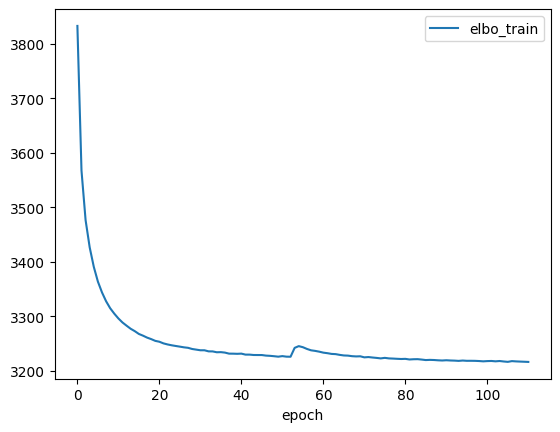

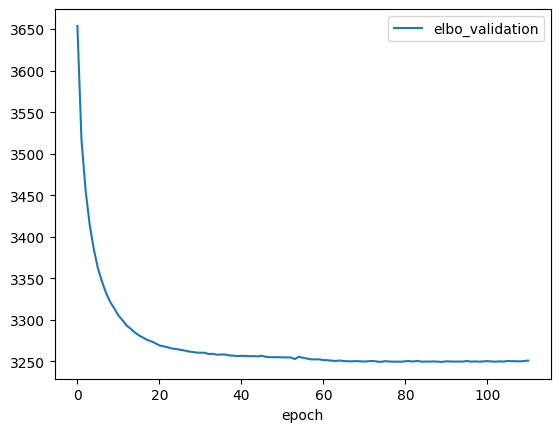

In [25]:
model.history["elbo_train"].plot()
model.history["elbo_validation"].plot()

In [26]:
# get latent
adata.obsm["salient_rep"] = model.get_latent_representation(adata, representation_kind="salient")
# umap
sc.pp.neighbors(adata, use_rep="salient_rep")
sc.tl.umap(adata)
adata.obsm["X_salient_umap"] = adata.obsm["X_umap"].copy()

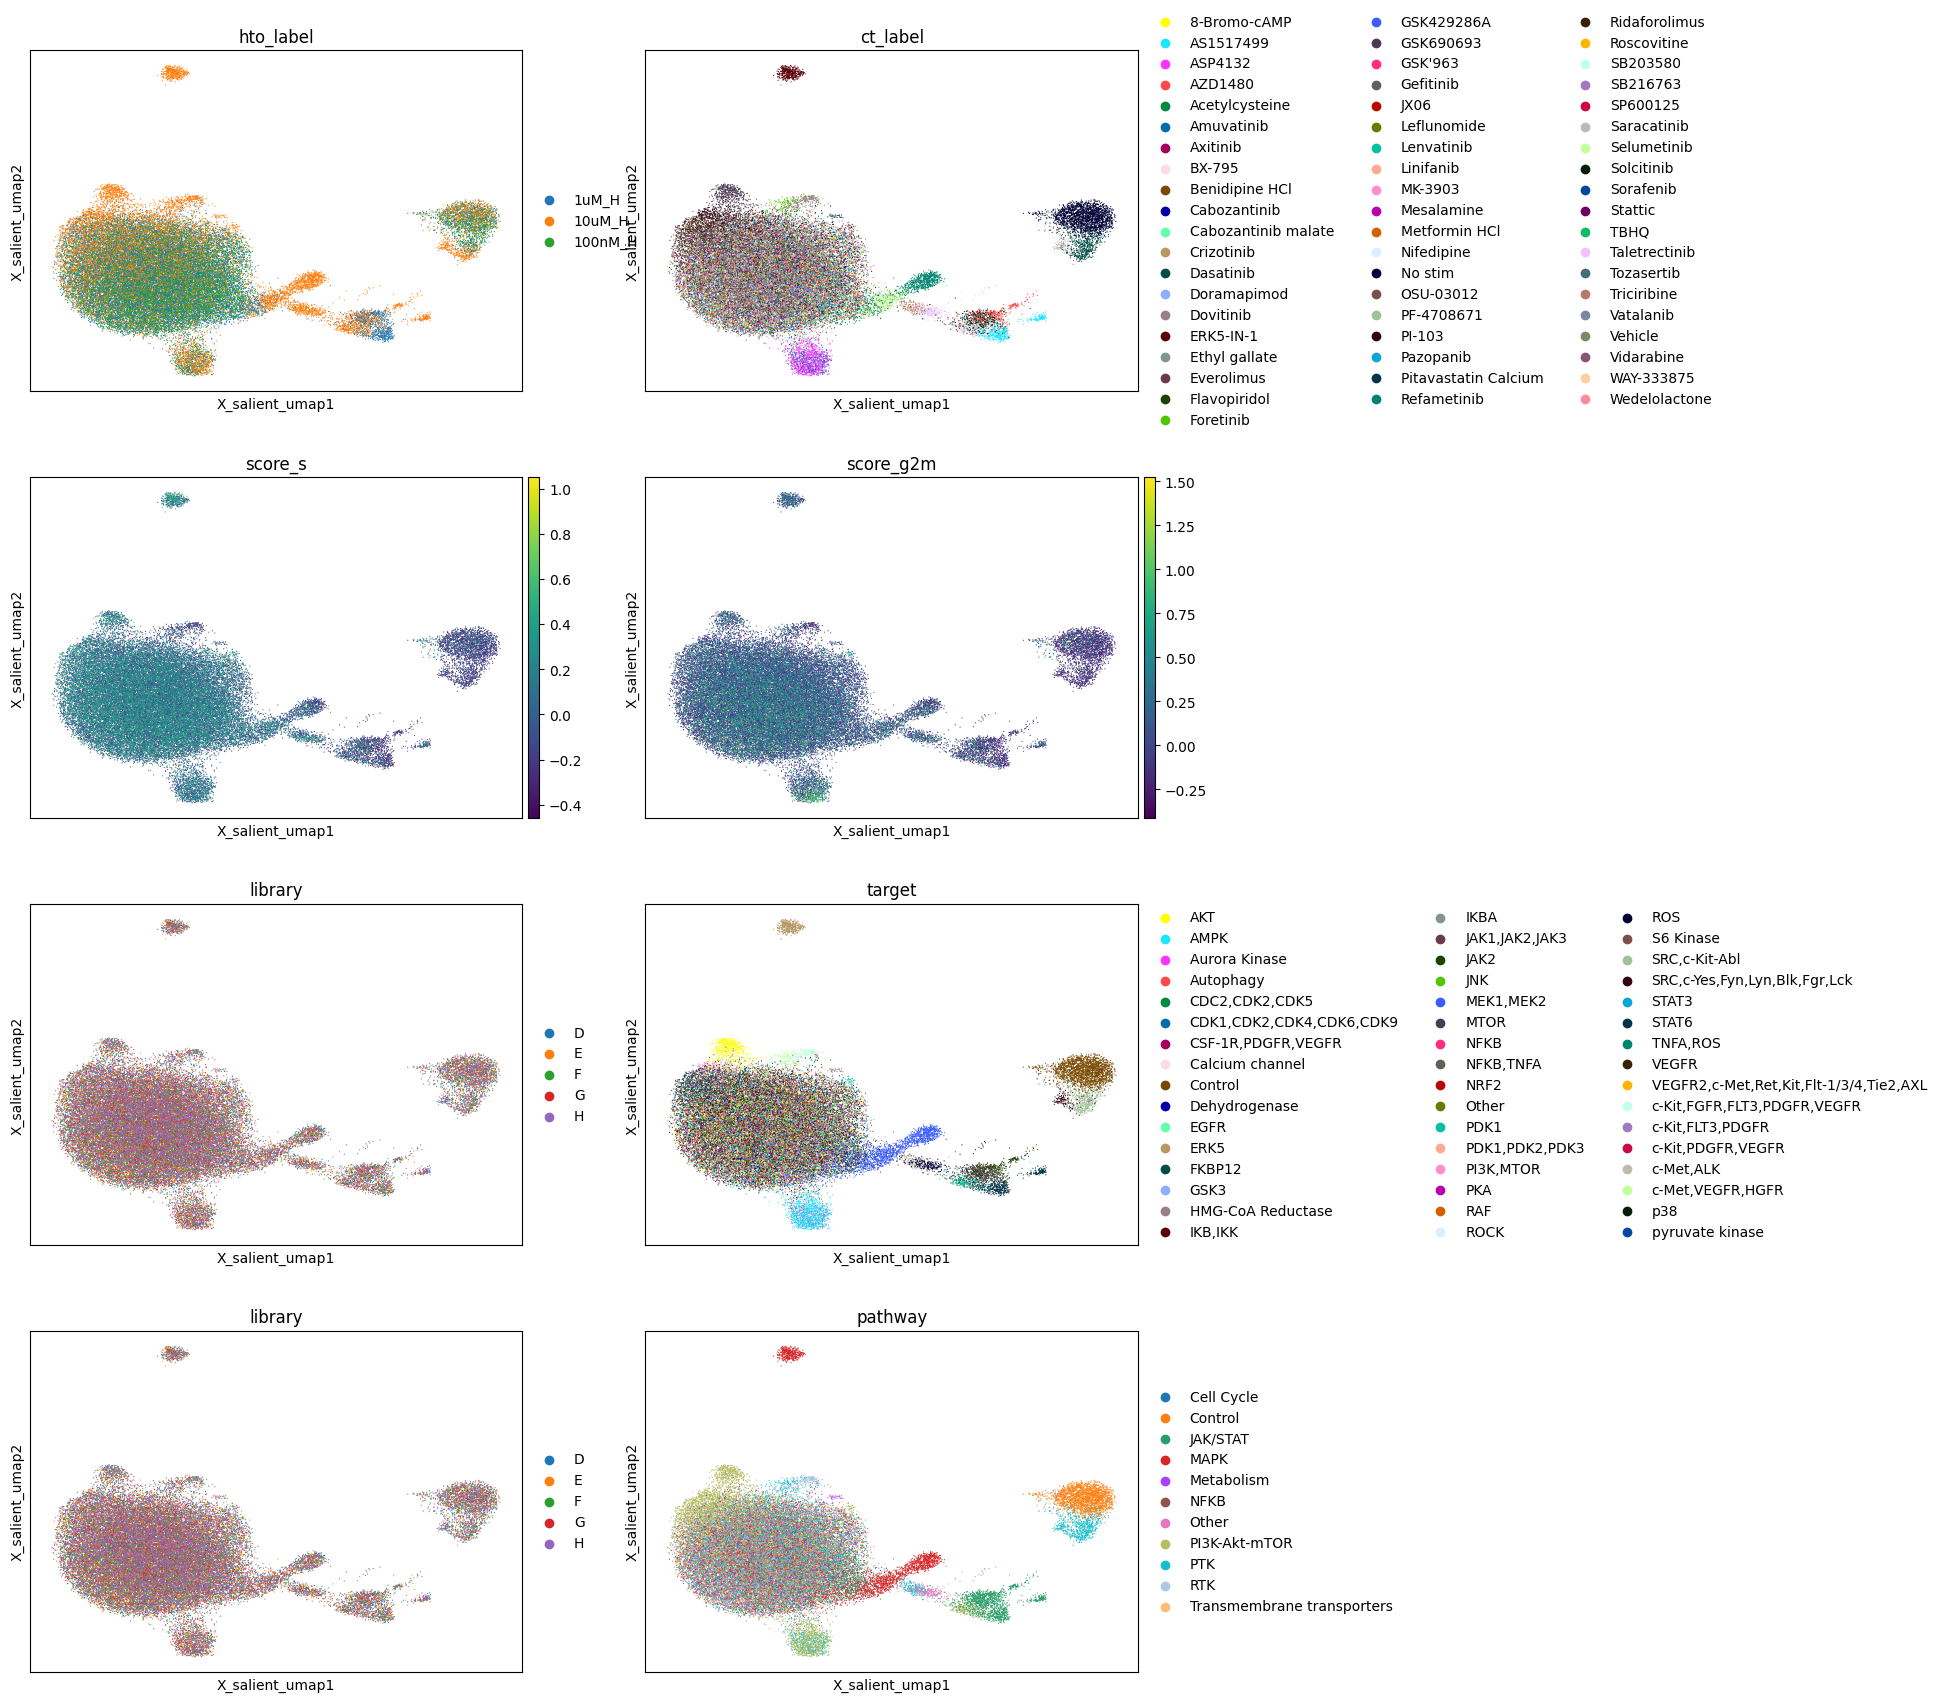

In [27]:
# quick glance at latent space
sc.pl.embedding(
    adata,
    basis="X_salient_umap",
    color=["hto_label", "ct_label", "score_s", "score_g2m", "library", "target", "library", "pathway"],
    ncols=2,
)